<a href="https://colab.research.google.com/github/henryparfait/kinyarwanda-news-classifier/blob/main/notebooks/05_error_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Evaluation and Error Analysis

**Goal:** understand *why* the models behave the way they do, not just how well they score. We compare the best model of each family on the same test set:

- **Best baseline** (classical ML), **best BiLSTM**, and **best Transformer**

Analyses:
1. Per-class F1 for each model vs. how much training data each class had
2. Which articles each model gets right or wrong (agreement)
3. The most frequent confusions
4. Whether the Transformer's confidence is trustworthy
5. Whether long articles (truncation) cause more errors
6. **Shortcut test:** does performance depend on source/byline words (e.g. *muhabura rw*, *yanditswe na*) rather than topic?


## Step 1: Load predictions from all three model families

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, f1_score, accuracy_score

PROJECT_DIR = '/content/drive/MyDrive/kinyarwanda-news-classifier'
DATA_DIR, FIG_DIR = f'{PROJECT_DIR}/data', f'{PROJECT_DIR}/figures'
RESULTS_DIR, MODEL_DIR = f'{PROJECT_DIR}/results', f'{PROJECT_DIR}/models'
SEED = 42

id2name = {int(k): v for k, v in json.load(open(f'{DATA_DIR}/label_map.json'))['id2name'].items()}
NAMES = [id2name[i] for i in sorted(id2name)]
test = pd.read_csv(f'{DATA_DIR}/test_dedup.csv')
train = pd.read_csv(f'{DATA_DIR}/train.csv')
split_counts = pd.read_csv(f'{RESULTS_DIR}/split_counts.csv', index_col=0)

preds = {'Best baseline': pd.read_csv(f'{RESULTS_DIR}/best_baseline_test_predictions.csv'),
         'Best BiLSTM': pd.read_csv(f'{RESULTS_DIR}/best_bilstm_test_predictions.csv'),
         'Best Transformer': pd.read_csv(f'{RESULTS_DIR}/best_transformer_test_predictions.csv')}
for name, df in preds.items():
    assert len(df) == len(test) and (df['text'].values == test['text'].values).all(), f'{name}: test order mismatch'
    m = (df['true'] == df['pred']).mean()
    mf = f1_score(df['true'], df['pred'], labels=NAMES, average='macro', zero_division=0)
    print(f'{name:18s} accuracy {m:.4f} | macro-F1 {mf:.4f}')

Mounted at /content/drive
Best baseline      accuracy 0.7428 | macro-F1 0.5773
Best BiLSTM        accuracy 0.6848 | macro-F1 0.5132
Best Transformer   accuracy 0.7546 | macro-F1 0.5810


## Step 2: Per-class F1 vs. amount of training data
If F1 tracks the training count closely, data scarcity is the main problem. If a class with plenty of data still scores badly, the problem is the class itself (ambiguity or overlap with another category).

,Best baseline,Best BiLSTM,Best Transformer,train_count,test_count
politic,0.625,0.638,0.656,1591,315
economy,0.558,0.482,0.602,998,174
health,0.656,0.492,0.669,976,272
entertainment,0.834,0.828,0.849,900,774
sport,0.946,0.919,0.953,878,744
religion,0.771,0.728,0.765,401,256
relationship,0.819,0.663,0.837,380,340
history,0.126,0.119,0.159,196,11
technology,0.674,0.607,0.648,135,103
education,0.109,0.240,0.069,104,70


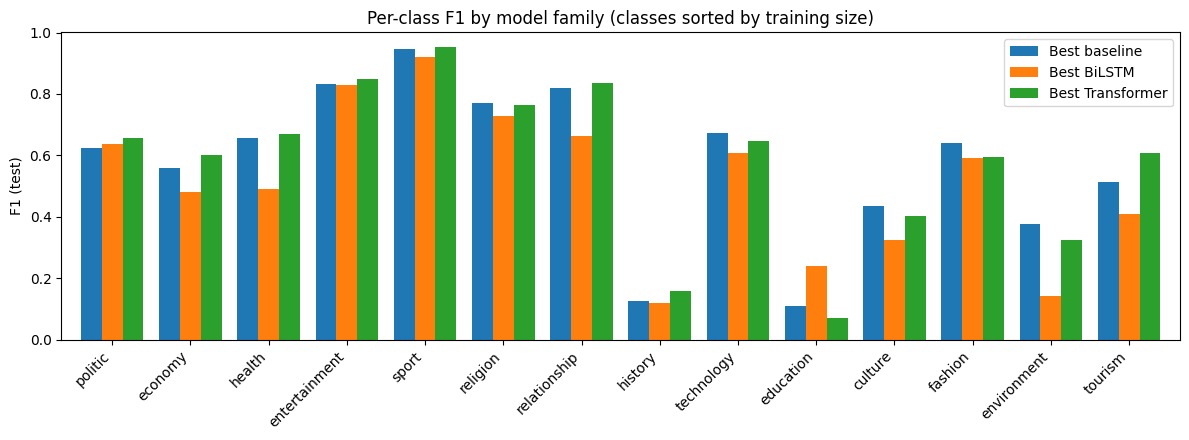

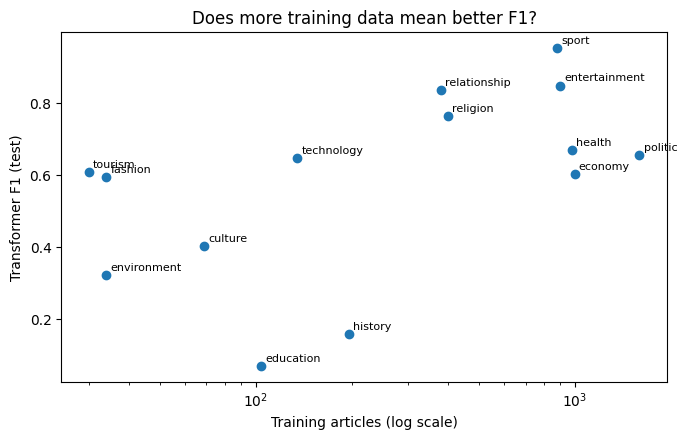

Correlation between log(train count) and Transformer F1: 0.52


In [ ]:
f1_tbl = pd.DataFrame(index=NAMES)
for name, df in preds.items():
    _, _, f, _ = precision_recall_fscore_support(df['true'], df['pred'], labels=NAMES, zero_division=0)
    f1_tbl[name] = f.round(3)
f1_tbl['train_count'] = split_counts['train'].reindex(NAMES).values
f1_tbl['test_count'] = split_counts['test_dedup'].reindex(NAMES).values
f1_tbl = f1_tbl.sort_values('train_count', ascending=False)
f1_tbl.to_csv(f'{RESULTS_DIR}/per_class_f1_comparison.csv')
display(f1_tbl)

ax = f1_tbl[list(preds)].plot.bar(figsize=(12, 4.5), width=0.8)
ax.set_ylabel('F1 (test)'); ax.set_title('Per-class F1 by model family (classes sorted by training size)')
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/per_class_f1_comparison.png', dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(f1_tbl['train_count'], f1_tbl['Best Transformer'])
for cat, r in f1_tbl.iterrows():
    ax.annotate(cat, (r['train_count'], r['Best Transformer']), fontsize=8, xytext=(3, 3), textcoords='offset points')
ax.set_xscale('log'); ax.set_xlabel('Training articles (log scale)'); ax.set_ylabel('Transformer F1 (test)')
ax.set_title('Does more training data mean better F1?'); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/f1_vs_train_size.png', dpi=200); plt.show()
corr = np.corrcoef(np.log(f1_tbl['train_count']), f1_tbl['Best Transformer'])[0, 1]
print(f'Correlation between log(train count) and Transformer F1: {corr:.2f}')

## Step 3: Agreement between model families
Articles that **all** models get wrong are often genuinely ambiguous or mislabelled. Articles that only the Transformer gets right show what pretraining adds.

In [ ]:
correct = pd.DataFrame({name: (df['true'] == df['pred']).values for name, df in preds.items()})
pattern = correct.apply(lambda r: ' / '.join(('✓' if v else '✗') for v in r), axis=1)
agree = pattern.value_counts().rename_axis('Baseline / BiLSTM / Transformer').reset_index(name='articles')
agree['percent'] = (100 * agree['articles'] / len(test)).round(1)
agree.to_csv(f'{RESULTS_DIR}/model_agreement.csv', index=False)
agree

,Baseline / BiLSTM / Transformer,articles,percent
0,✓ / ✓ / ✓,2025,58.5
1,✗ / ✗ / ✗,545,15.7
2,✓ / ✗ / ✓,332,9.6
3,✗ / ✓ / ✓,138,4.0
4,✓ / ✓ / ✗,120,3.5
5,✗ / ✗ / ✓,119,3.4
6,✓ / ✗ / ✗,96,2.8
7,✗ / ✓ / ✗,89,2.6


## Step 4: Most frequent confusions (best Transformer)

In [ ]:
tf = preds['Best Transformer'].copy()
tf['n_words'] = test['n_words'].values
err = tf[tf['true'] != tf['pred']]
pairs = err.groupby(['true', 'pred']).size().rename('errors').reset_index()
pairs['% of true class'] = (100 * pairs['errors'] / pairs['true'].map(tf['true'].value_counts())).round(1)
pairs = pairs.sort_values('errors', ascending=False).head(12)
pairs.to_csv(f'{RESULTS_DIR}/top_confusions.csv', index=False)
print(f'Total Transformer errors: {len(err)} of {len(tf)} ({len(err)/len(tf):.1%})')
pairs

Total Transformer errors: 850 of 3464 (24.5%)


,true,pred,errors,% of true class
6,culture,history,39,28.3
40,entertainment,religion,38,4.9
29,education,relationship,32,45.7
73,politic,economy,31,9.8
43,environment,economy,30,30.0
54,fashion,entertainment,27,29.7
44,environment,health,27,27.0
65,health,politic,26,9.6
77,politic,history,25,7.9
20,economy,technology,23,13.2


## Step 5: Is the model's confidence trustworthy?
If high-confidence predictions are almost always right, the app can safely warn the user when confidence is low.

In [ ]:
bins = [0, 0.5, 0.7, 0.9, 1.0001]
tf['conf_bin'] = pd.cut(tf['confidence'], bins, labels=['<50%', '50-70%', '70-90%', '>90%'], right=False)
calib = tf.groupby('conf_bin', observed=False).apply(
    lambda g: pd.Series({'articles': len(g), 'accuracy': (g['true'] == g['pred']).mean() if len(g) else np.nan})).round(3)
calib.to_csv(f'{RESULTS_DIR}/confidence_vs_accuracy.csv')
display(calib)
print(f"Errors made with >90% confidence: {((tf['confidence'] >= 0.9) & (tf['true'] != tf['pred'])).sum()}")

/tmp/ipykernel_677/109151489.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  calib = tf.groupby('conf_bin', observed=False).apply(


,articles,accuracy
conf_bin,,
<50%,139.0,0.295
50-70%,321.0,0.439
70-90%,488.0,0.510
>90%,2516.0,0.868


Errors made with >90% confidence: 333


## Step 6: Do long articles cause more errors?

In [ ]:
len_bins = [0, 200, 400, 600, 100000]
len_labels = ['<200 words', '200-400', '400-600', '>600']
rows = []
for name, df in preds.items():
    b = pd.cut(test['n_words'], len_bins, labels=len_labels)
    acc = (df['true'] == df['pred']).groupby(b, observed=False).mean()
    rows.append(acc.rename(name))
len_tbl = pd.concat(rows, axis=1).round(3)
len_tbl['articles'] = pd.cut(test['n_words'], len_bins, labels=len_labels).value_counts().reindex(len_labels).values
len_tbl.to_csv(f'{RESULTS_DIR}/accuracy_by_length.csv')
len_tbl

,Best baseline,Best BiLSTM,Best Transformer,articles
n_words,,,,
<200 words,0.773,0.723,0.794,816
200-400,0.770,0.684,0.779,1704
400-600,0.721,0.687,0.726,598
>600,0.575,0.595,0.592,346


## Step 7: Shortcut analysis, part A: how are source/byline words distributed?
Notebook 02 showed that the baseline's top features include website names and bylines. If a marker appears mostly in one category in the **training** set, a model can use it as a shortcut instead of reading the topic.

In [ ]:
MARKERS = {
    'muhabura (news site)': r'\bmuhabura\b',
    'yanditswe na ("written by")': r'\byanditswe na\b',
    'src': r'\bsrc\b',
    'caption': r'\bcaption\b',
    'views': r'\bviews\b',
}
rows = []
for split_name, df in [('train', train), ('test', test)]:
    low = df['text'].str.lower()
    labels = df['label_id'].map(id2name)
    for mname, pat in MARKERS.items():
        has = low.str.contains(pat, regex=True)
        share = has.groupby(labels).mean().reindex(NAMES)
        rows.append({'split': split_name, 'marker': mname, 'articles_with_marker': int(has.sum()),
                     **{c: round(100 * v, 1) for c, v in share.items()}})
marker_tbl = pd.DataFrame(rows)
marker_tbl.to_csv(f'{RESULTS_DIR}/source_marker_distribution.csv', index=False)
print('% of articles in each category that contain the marker:')
marker_tbl

% of articles in each category that contain the marker:


,split,marker,articles_with_marker,politic,sport,economy,health,entertainment,history,technology,tourism,culture,fashion,religion,environment,education,relationship
0,train,muhabura (news site),1306,26.0,0.1,40.5,41.0,0.3,42.3,0.0,0.0,0.0,0.0,0.0,2.9,0.0,0.0
1,train,"yanditswe na (""written by"")",781,12.6,0.0,34.1,20.1,0.1,20.9,0.0,0.0,0.0,0.0,0.5,0.0,0.0,0.3
2,train,src,253,3.8,4.6,5.6,3.1,2.3,5.6,5.2,0.0,0.0,0.0,0.2,0.0,4.8,5.8
3,train,caption,102,1.4,0.2,0.0,1.6,0.2,2.6,0.7,0.0,0.0,0.0,4.5,0.0,34.6,0.0
4,train,views,62,0.0,1.0,0.0,0.5,1.4,6.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.1
5,test,muhabura (news site),1156,0.3,54.4,0.6,0.0,51.2,27.3,0.0,6.6,0.0,0.0,40.6,0.0,0.0,70.9
6,test,"yanditswe na (""written by"")",1143,0.6,53.4,0.0,0.0,54.8,0.0,0.0,0.0,0.0,0.0,34.8,0.0,0.0,67.9
7,test,src,91,7.3,1.9,6.3,5.1,1.2,0.0,1.0,0.0,2.2,0.0,2.3,4.0,4.3,0.9
8,test,caption,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,test,views,1,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Step 8: Shortcut analysis, part B: what happens if we remove those words?
We delete the marker words from every test article and predict again, **without retraining**. A large drop means the model relied on them, and a small drop means it reads the actual content.

In [ ]:
import joblib
STRIP_RE = re.compile('|'.join(MARKERS.values()), flags=re.IGNORECASE)
test_stripped = test['text'].str.replace(STRIP_RE, ' ', regex=True).str.replace(r'\s+', ' ', regex=True)
y_true = test['label_id'].map(id2name).values
shortcut_rows = []

baseline = joblib.load(f'{MODEL_DIR}/best_baseline.joblib')
for cond, texts in [('original', test['text']), ('markers removed', test_stripped)]:
    p = pd.Series(baseline.predict(texts)).map(id2name).values
    shortcut_rows.append({'model': 'Best baseline', 'condition': cond, 'accuracy': accuracy_score(y_true, p),
                          'macro_f1': f1_score(y_true, p, labels=NAMES, average='macro', zero_division=0)})

try:
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    tdir = f'{MODEL_DIR}/best_transformer'
    max_len = json.load(open(f'{tdir}/run_info.json'))['max_len']
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print('Transformer shortcut test on', dev, '(on CPU this takes ~10-15 min)')
    tok = AutoTokenizer.from_pretrained(tdir)
    mdl = AutoModelForSequenceClassification.from_pretrained(tdir).to(dev).eval()
    def tpredict(texts, bs=32):
        out = []
        for i in range(0, len(texts), bs):
            enc = tok(list(texts[i:i+bs]), truncation=True, max_length=max_len, padding=True, return_tensors='pt').to(dev)
            with torch.no_grad():
                out.extend(mdl(**enc).logits.argmax(-1).cpu().tolist())
        return np.array([id2name[i] for i in out])
    for cond, texts in [('original', test['text'].tolist()), ('markers removed', test_stripped.tolist())]:
        p = tpredict(texts)
        shortcut_rows.append({'model': 'Best Transformer', 'condition': cond, 'accuracy': accuracy_score(y_true, p),
                              'macro_f1': f1_score(y_true, p, labels=NAMES, average='macro', zero_division=0)})
except Exception as e:
    print('Transformer part skipped:', e)

shortcut_tbl = pd.DataFrame(shortcut_rows).round(4)
shortcut_tbl.to_csv(f'{RESULTS_DIR}/shortcut_test.csv', index=False)
shortcut_tbl

Transformer shortcut test on cuda (on CPU this takes ~10-15 min)


Loading weights:   0%|          | 0/137 [00:00<?, ?it/s]

,model,condition,accuracy,macro_f1
0,Best baseline,original,0.7428,0.5773
1,Best baseline,markers removed,0.7474,0.5801
2,Best Transformer,original,0.7549,0.5813
3,Best Transformer,markers removed,0.7549,0.5812


## Step 9: Error sheet for manual review.

In [ ]:
sheet = []
for _, pr in pairs.head(10).iterrows():
    sub = err[(err['true'] == pr['true']) & (err['pred'] == pr['pred'])].sample(
        min(3, int(pr['errors'])), random_state=SEED)
    for idx, r in sub.iterrows():
        sheet.append({'test_index': idx, 'true': r['true'], 'pred': r['pred'], 'confidence': round(r['confidence'], 3),
                      'n_words': r['n_words'], 'excerpt': ' '.join(r['text'].split()[:80]),
                      'error_type': '', 'comment': ''})
sheet = pd.DataFrame(sheet)
sheet.to_csv(f'{RESULTS_DIR}/error_review_sheet.csv', index=False)
print(len(sheet), 'errors exported to', f'{RESULTS_DIR}/error_review_sheet.csv')
sheet.head()

30 errors exported to /content/drive/MyDrive/kinyarwanda-news-classifier/results/error_review_sheet.csv


,test_index,true,pred,confidence,n_words,excerpt,error_type,comment
0,2987,culture,history,0.933,553,Imiryango yahamije ubuhangange mu mateka: Igic...,,
1,3002,culture,history,0.933,518,Amwe mu magambo akomeye yavuzwe na Bob Marley ...,,
2,2187,culture,history,0.962,294,AMATEKA-Uko umwami yimaga ingoma mu Rwanda. Am...,,
3,2833,entertainment,religion,0.940,602,Ibitwenge byari byose! Miss Naomie ari mu bate...,,
4,2853,entertainment,religion,0.990,432,James na Daniella n'abo bazafatanya bahishuye ...,,


## Step 10: Showcase examples
Three confident correct predictions and three errors, with excerpts.

In [ ]:
pd.set_option('display.max_colwidth', 300)
good = tf[tf['true'] == tf['pred']].sort_values('confidence', ascending=False)
good = good.groupby('true').head(1).head(3)
bad = err.sort_values('confidence', ascending=False).head(3)
show = pd.concat([good.assign(kind='correct'), bad.assign(kind='error')])
show['excerpt'] = show['text'].str.split().str[:45].str.join(' ') + ' …'
show = show[['kind', 'true', 'pred', 'confidence', 'excerpt']]
show.to_csv(f'{RESULTS_DIR}/showcase_examples.csv', index=False)
show

,kind,true,pred,confidence,excerpt
1361,correct,sport,sport,0.9952,"Amabubi U20: N'ubwo barajya mu Misiri ariko biragoye cyane kuzana Intsinzi. Kayiranga Baptiste utoza ikipe y'igihugu Amabubi U20, yahamagaye abakinnyi 20 ajyana mu Misiri mu mukino wo kwishyura wo gushaka igikombe cya Afurika, gutsinda Misiri iwayo yaratsinze Amavubi i Kigali, bamwe babigererany..."
904,correct,relationship,relationship,0.9939,"Abanyabwenge bashyize ibyiciro biranga Abakobwa babi ni biranga abeza!. Umukobwa uteye gutya aba yujuje ibisabwa byose kugira ngo umukobwa abe mwiza ku mubiri.Aba ari mwiza, ashitura, avuga neza mbese byose aba abyujuje. Akoresha ubu bwiza ngo akurure abasore/abagabo. Akunda kuba afite inshuti n..."
631,correct,religion,religion,0.9938,"Bishop Rugagi yahishuye ko gusenga cyane bidatuma itorero ryubahwa ahubwo ko ryubahishwa n'ubutunzi =business. Ku mbuga nkoranyambaga hasakaye amashusho agaragaza Umushumba mukuru w'itorero Redeemed Gospel Church, Bishop Innocent Rugagi avuga ko kubahwa kw'amatorero akomeye ku isi bidaterwa n'im..."
107,error,entertainment,sport,0.9949,"Umutoza Mashami Vincent yaretse umuryango abakinnyi 5 mu Mavubi yitegura guhangana na Côte d'Ivoire. Umutoza w'ikipe y'igihugu Amavubi, Mashami Vincent, yamaze gusezerera abakinnyi batanu mu bari bitabiriye umwiherero utegura umukino wa Côte d'Ivoire. Amavubi afite urugamba rutoroshye kuri iki C..."
43,error,entertainment,sport,0.9940,Amerika yatsinze Ubwongereza ijya ku mukino wa nyuma w'igikombe cy'isi cy'abagore. Inzozi z'Abongerezakazi zo kugera ku mukino wa nyuma w'igikombe cy'isi cy'abagore zaburijwemo ubwo umunyezamu yakuragamo penaliti ya Steph Houghton yari gutuma banganya na Amerika. Muri uyu mukino warangiye Amerik...
60,error,entertainment,sport,0.9940,"APR FC ikuye amanota y'ingenzi I Huye,nyuma yo gutsinda igitego ku munota. APR FC ikuye amanota y'ingenzi I Huye,nyuma yo gutsinda igitego ku munota wa nyuma cyabahesheje intsinzi ubwo bari bahanganye na Mukura VS yabagoye ku buryo bukomeye ibifashijwemo na Sibomana Patrick wahoze akinira iyi …"
